In [2]:
import pandas as pd
import numpy as np

In [4]:
from google.colab import files
uploaded = files.upload()

Saving app_user_behavior_dataset.csv to app_user_behavior_dataset.csv


In [5]:
df = pd.read_csv('app_user_behavior_dataset.csv')
df.head()

,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,...,days_since_last_login,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,...,20,Basic,9,5,2,NaN,0.31,55.79,1152,Referral
1,100001,46,Male,UK,iOS,1.0,8,24.44,42.03,7,...,7,Free,8,3,3,3.0,0.87,82.39,1059,Email Campaign
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,...,33,Free,11,6,1,2.0,0.63,42.49,678,Google Ads
3,100003,25,Male,India,Android,2.0,5,3.98,65.38,16,...,17,Basic,6,3,1,3.0,0.43,62.81,92,Organic
4,100004,38,Male,Australia,Android,1.0,10,12.85,57.06,13,...,21,Basic,4,4,2,5.0,0.43,38.21,772,Email Campaign


In [6]:
print(df.shape)
print(df.isnull().sum())

(50000, 25)
user_id                             0
age                                 0
gender                              0
country                             0
device_type                         0
app_version                         0
sessions_per_week                   0
avg_session_duration_min            0
daily_active_minutes                0
feature_clicks_per_session          0
notifications_opened_per_week       0
in_app_search_count                 0
pages_viewed_per_session            0
crash_events_last_30_days           0
support_tickets_raised              0
days_since_last_login               0
subscription_type                   0
ads_clicked_last_30_days            0
content_downloads                   0
social_shares                       0
rating_given                     5022
churn_risk_score                    0
engagement_score                    0
account_age_days                    0
marketing_source                    0
dtype: int64


In [7]:
df['rating_given'] = df['rating_given'].fillna(df['rating_given'].median())
print("Cleaning mudinju!")

Cleaning mudinju!


In [8]:
features = ['sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes', 'engagement_score']
X = df[features]
print(X.head())

   sessions_per_week  avg_session_duration_min  daily_active_minutes  \
0                  5                      3.41                 52.71   
1                  8                     24.44                 42.03   
2                 12                      5.34                 76.69   
3                  5                      3.98                 65.38   
4                 10                     12.85                 57.06   

   engagement_score  
0             55.79  
1             82.39  
2             42.49  
3             62.81  
4             38.21  


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaling mudinju! Ready for clustering!")

Scaling mudinju! Ready for clustering!


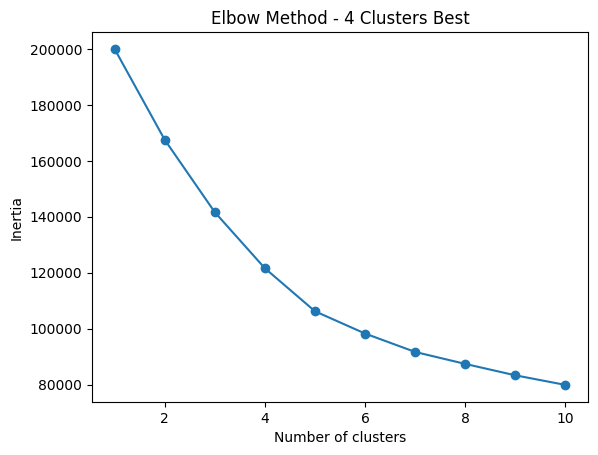

In [10]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method - 4 Clusters Best')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

In [11]:
final_model = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = final_model.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
3    15000
1    14658
0    12654
2     7688
Name: count, dtype: int64


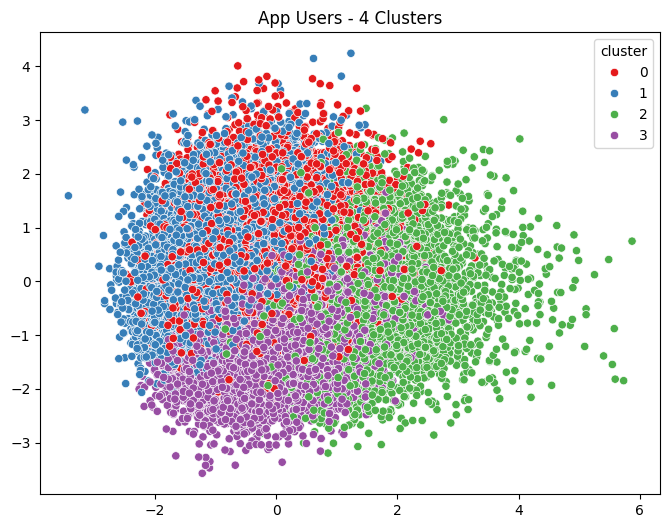

In [12]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
sns.scatterplot(x=pca_data[:,0], y=pca_data[:,1], hue=df['cluster'], palette='Set1')
plt.title('App Users - 4 Clusters')
plt.show()